<a href="https://colab.research.google.com/github/GOWTHAMVANTAKULA/DeepCSAT_E_Commerce_Customer_Satisfaction_Score_Prediction/blob/main/DeepCSAT_E_Commerce_Customer_Satisfaction_Score_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/DeepCSAT: E-Commerce Customer Satisfaction Score Prediction/eCommerce_Customer_support_data.csv')


In [ ]:
df.head(5)

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01-08-2023 11:13,01-08-2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01-08-2023 12:52,01-08-2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01-08-2023 20:16,01-08-2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01-08-2023 20:56,01-08-2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01-08-2023 10:30,01-08-2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


In [ ]:
# target varavale
print(df['CSAT Score'].unique())
print(df['CSAT Score'].nunique())

[5 4 1 3 2]
5


In [ ]:
# no of rows
len(df)

85907

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

In [ ]:
# drop Duplicates

df = df.drop_duplicates()

In [ ]:
# missing value percentage

df.isnull().sum().sort_values(ascending=False)*100/len(df)

,0
connected_handling_time,99.718300
Customer_City,80.119199
Product_category,79.983005
Item_price,79.971364
order_date_time,79.962052
Customer Remarks,66.542889
Order_id,21.222950
Unique id,0.000000
Sub-category,0.000000
category,0.000000


In [ ]:
# filling the missing values

df.fillna({'Customer Remarks' : 'No Remarks'},inplace = True)

In [ ]:
for i in df.columns:
  if df[i].dtype == 'object':
    df[i].fillna('Unknown',inplace = True)

  else:
    df[i].fillna(df[i].median(),inplace = True)

/tmp/ipykernel_616/349505532.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[i].fillna('Unknown',inplace = True)
/tmp/ipykernel_616/349505532.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.meth

In [ ]:
df.isnull().sum()

,0
Unique id,0
channel_name,0
category,0
Sub-category,0
Customer Remarks,0
Order_id,0
order_date_time,0
Issue_reported at,0
issue_responded,0
Survey_response_Date,0


In [ ]:
# finding the time for responding

def time_diff(row):
  try:
    t1 = pd.to_datetime(row['Issue_reported at'])
    t2 = pd.to_datetime(row['issue_responded'])
    return(t2-t1).total_seconds()/60
  except:
    return 0



In [ ]:
df['Handling_Time_min'] = df.apply(time_diff,axis = 1)

/tmp/ipykernel_616/3277024626.py:5: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  t1 = pd.to_datetime(row['Issue_reported at'])
/tmp/ipykernel_616/3277024626.py:6: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  t2 = pd.to_datetime(row['issue_responded'])


In [ ]:
df.columns

Index(['Unique id', 'channel_name', 'category', 'Sub-category',
       'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at',
       'issue_responded', 'Survey_response_Date', 'Customer_City',
       'Product_category', 'Item_price', 'connected_handling_time',
       'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift',
       'CSAT Score', 'Handling_Time_min'],
      dtype='object')

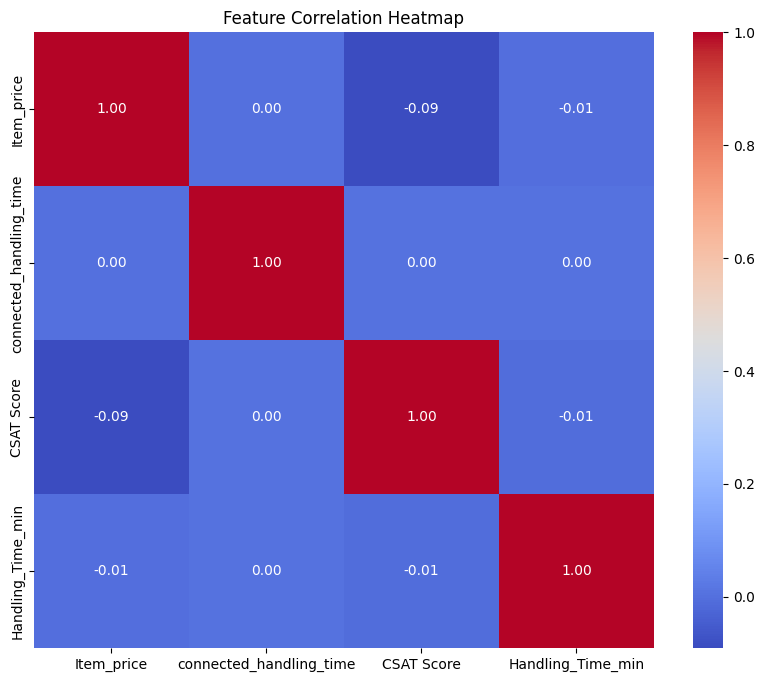

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
# Correlation Heatmap
correlation_matrix = df.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Feature Correlation Heatmap')
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# 5. Preprocessing
selected_features = [
    'channel_name', 'category', 'Sub-category',
    'Product_category', 'Item_price', 'Agent_name', 'Supervisor', 'Manager',
    'Tenure Bucket', 'Agent Shift', 'Handling_Time_min'
]
target = 'CSAT Score'

for col in ['channel_name','category','Sub-category','Product_category','Agent_name','Supervisor','Manager','Tenure Bucket','Agent Shift']:
    df[col] = LabelEncoder().fit_transform(df[col])

scaler = StandardScaler()
df[['Item_price','Handling_Time_min']] = scaler.fit_transform(df[['Item_price','Handling_Time_min']])

X = df[selected_features]
y = df[target]

In [ ]:
# 6. Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
for i in (X_train, X_test, y_train, y_test):
    print(i.dtypes)

channel_name           int64
category               int64
Sub-category           int64
Product_category       int64
Item_price           float64
Agent_name             int64
Supervisor             int64
Manager                int64
Tenure Bucket          int64
Agent Shift            int64
Handling_Time_min    float64
dtype: object
channel_name           int64
category               int64
Sub-category           int64
Product_category       int64
Item_price           float64
Agent_name             int64
Supervisor             int64
Manager                int64
Tenure Bucket          int64
Agent Shift            int64
Handling_Time_min    float64
dtype: object
int64
int64


In [ ]:
# ANN Regression Model
model = Sequential([
    Dense(64, input_dim=X_train.shape[1], activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])


In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10)

history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2,
                    callbacks=[early_stop], verbose=0)

In [ ]:
# ANN Regression Results
y_pred = model.predict(X_test).flatten()
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Test MSE: {mse:.3f}, MAE: {mae:.3f}, R2: {r2:.3f}")

537/537 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Test MSE: 1.891, MAE: 1.093, R2: -0.001


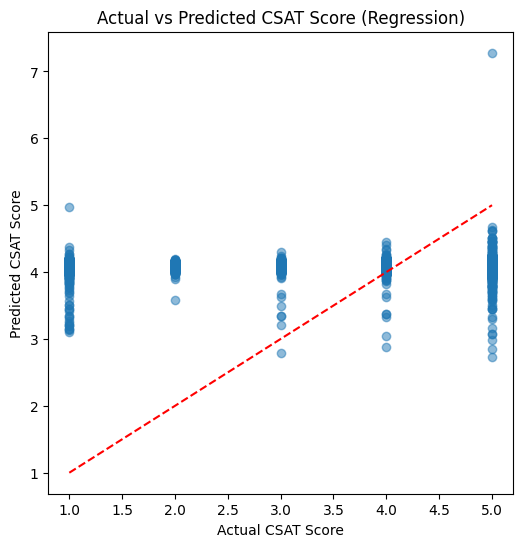

In [ ]:
# Actual vs Predicted Plot
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual CSAT Score')
plt.ylabel('Predicted CSAT Score')
plt.title('Actual vs Predicted CSAT Score (Regression)')
plt.show()


In [ ]:
# 8. ANN Classification (CSAT High/Low)
# Create binary CSAT: High (>=4), Low (<4)
df['CSAT_High'] = (df[target] >= 4).astype(int)
y_class = df['CSAT_High']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)

model_class = Sequential([
    Dense(64, input_dim=X_train_c.shape[1], activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_class.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])




In [ ]:
early_stop_c = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10)
history_c = model_class.fit(X_train_c, y_train_c, epochs=50, batch_size=32, validation_split=0.2, callbacks=[early_stop_c], verbose=0)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Predictions
y_pred_prob = model_class.predict(X_test_c)

y_pred_class = (y_pred_prob > 0.5).astype(int).flatten()

# Actual values
y_test_actual = np.array(y_test_c).flatten()

# Classification report
print(classification_report(
    y_test_actual,
    y_pred_class,
    target_names=['Low', 'High'],
    zero_division=0
))

537/537 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
              precision    recall  f1-score   support

         Low       0.54      0.01      0.02      2971
        High       0.83      1.00      0.91     14211

    accuracy                           0.83     17182
   macro avg       0.68      0.50      0.46     17182
weighted avg       0.78      0.83      0.75     17182



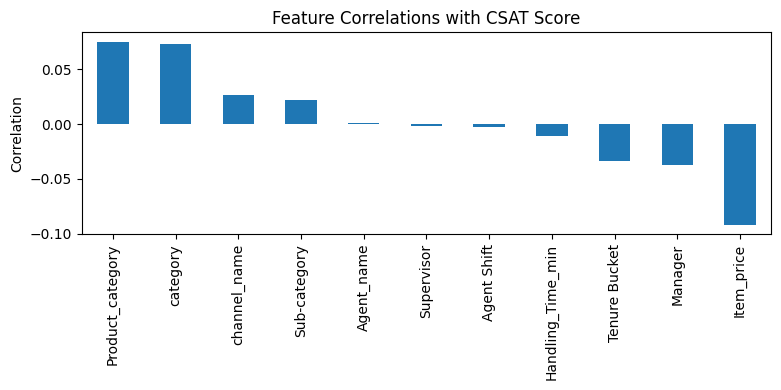

In [ ]:
# Feature Importance (Correlation with CSAT Score)
corr = pd.DataFrame(X_train, columns=X.columns).corrwith(pd.Series(y_train))
plt.figure(figsize=(8,4))
corr.sort_values(ascending=False).plot(kind='bar')
plt.ylabel('Correlation')
plt.title('Feature Correlations with CSAT Score')
plt.tight_layout()
plt.show()


In [ ]:
import joblib

# Save the Keras Neural Network Classification Model natively (Recommended)
model_class.save('ann_classification_model.keras')
print("Saved Keras classification model to 'ann_classification_model.keras'")

# Also demonstrating how to save preprocessors (like the scaler) using joblib
# since you would need them to preprocess new data during inference
joblib.dump(scaler, 'scaler.joblib')
print("Saved StandardScaler to 'scaler.joblib'")

Saved Keras classification model to 'ann_classification_model.keras'
Saved StandardScaler to 'scaler.joblib'


In [ ]:
import sys
!pip install -q gradio tensorflow joblib pandas numpy

In [32]:
import gradio as gr
import tensorflow as tf
import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# 1. Load the trained model and scaler
model_class = tf.keras.models.load_model('ann_classification_model.keras')
scaler = joblib.load('scaler.joblib')

# Re-load or read the original dataset to get category names and fit our LabelEncoders
original_df = pd.read_csv('/content/drive/MyDrive/DeepCSAT: E-Commerce Customer Satisfaction Score Prediction/eCommerce_Customer_support_data.csv')

# Fill missing values to match training
original_df.fillna({'Customer Remarks' : 'No Remarks'}, inplace=True)
for i in original_df.columns:
    if original_df[i].dtype == 'object':
        original_df[i].fillna('Unknown', inplace=True)
    else:
        original_df[i].fillna(original_df[i].median(), inplace=True)

# Create and fit LabelEncoders for mapping user dropdown selections
label_encoders = {}
categorical_cols = [
    'channel_name', 'category', 'Sub-category',
    'Product_category', 'Agent_name', 'Supervisor',
    'Manager', 'Tenure Bucket', 'Agent Shift'
]

for col in categorical_cols:
    le = LabelEncoder()
    original_df[col] = le.fit_transform(original_df[col])
    label_encoders[col] = le

selected_features = [
    'channel_name', 'category', 'Sub-category',
    'Product_category', 'Item_price', 'Agent_name', 'Supervisor', 'Manager',
    'Tenure Bucket', 'Agent Shift', 'Handling_Time_min'
]

def predict_csat_v2(channel_name, category, sub_category, product_category, item_price, agent_name, supervisor, manager, tenure_bucket, agent_shift, handling_time_min):
    try:
        # Encode user string choices to original numeric labels
        encoded_channel = label_encoders['channel_name'].transform([channel_name])[0]
        encoded_category = label_encoders['category'].transform([category])[0]
        encoded_sub = label_encoders['Sub-category'].transform([sub_category])[0]
        encoded_prod = label_encoders['Product_category'].transform([product_category])[0]
        encoded_agent = label_encoders['Agent_name'].transform([agent_name])[0]
        encoded_super = label_encoders['Supervisor'].transform([supervisor])[0]
        encoded_manager = label_encoders['Manager'].transform([manager])[0]
        encoded_tenure = label_encoders['Tenure Bucket'].transform([tenure_bucket])[0]
        encoded_shift = label_encoders['Agent Shift'].transform([agent_shift])[0]

        # Convert inputs to a DataFrame
        input_data = pd.DataFrame([[
            float(encoded_channel),
            float(encoded_category),
            float(encoded_sub),
            float(encoded_prod),
            float(item_price),
            float(encoded_agent),
            float(encoded_super),
            float(encoded_manager),
            float(encoded_tenure),
            float(encoded_shift),
            float(handling_time_min)
        ]], columns=selected_features)

        # Scale numerical features
        input_data[['Item_price', 'Handling_Time_min']] = scaler.transform(input_data[['Item_price', 'Handling_Time_min']])

        # Make prediction
        prediction_prob = model_class.predict(input_data)[0][0]
        prediction_class = "High (>=4)" if prediction_prob > 0.5 else "Low (<4)"

        return f"Prediction: {prediction_class} (Probability of High CSAT: {prediction_prob:.2%})"
    except Exception as e:
        return f"Error during prediction: {str(e)}"

# Get list of unique original categories for dropdown menus
choices_dict = {col: list(label_encoders[col].classes_) for col in categorical_cols}

# Create the refined Gradio interface with Dropdown lists
interface_v2 = gr.Interface(
    fn=predict_csat_v2,
    inputs=[
        gr.Dropdown(choices=choices_dict['channel_name'], label="Channel Name", value=choices_dict['channel_name'][0]),
        gr.Dropdown(choices=choices_dict['category'], label="Category", value=choices_dict['category'][0]),
        gr.Dropdown(choices=choices_dict['Sub-category'], label="Sub-Category", value=choices_dict['Sub-category'][0]),
        gr.Dropdown(choices=choices_dict['Product_category'], label="Product Category", value=choices_dict['Product_category'][0]),
        gr.Number(label="Item Price (Original Value)", value=100.0),
        gr.Dropdown(choices=choices_dict['Agent_name'], label="Agent Name", value=choices_dict['Agent_name'][0]),
        gr.Dropdown(choices=choices_dict['Supervisor'], label="Supervisor", value=choices_dict['Supervisor'][0]),
        gr.Dropdown(choices=choices_dict['Manager'], label="Manager", value=choices_dict['Manager'][0]),
        gr.Dropdown(choices=choices_dict['Tenure Bucket'], label="Tenure Bucket", value=choices_dict['Tenure Bucket'][0]),
        gr.Dropdown(choices=choices_dict['Agent Shift'], label="Agent Shift", value=choices_dict['Agent_shift'] if 'Agent_shift' in choices_dict else choices_dict['Agent Shift'][0]),
        gr.Number(label="Handling Time min (Original Value)", value=15.0)
    ],
    outputs=gr.Textbox(label="CSAT Classification Result"),
    title="Refined E-Commerce Customer Satisfaction (CSAT) Predictor",
    description="Select values from the dropdown boxes to classify CSAT as High or Low."
)

interface_v2.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7c41b764e7f24af9ab.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://7c41b764e7f24af9ab.gradio.live
